# 02 · Replicação de Battisti & Sentelhas (2019)

*Characterizing Brazilian soybean-growing regions by water deficit patterns*, Field Crops Res. 240:95–105.

| Item | Artigo | Replicação |
|---|---|---|
| Clima | Xavier et al. (2015), grade 1°, 453 pontos, 1980–2013 | Xavier BR-DWGD (0,1°) via GEE; média dos 4 pixels em cada nó x,5°; **462 pontos digitalizados da Fig. 1** |
| Solos | 3 perfis (Tabela S1), raiz 80 cm, SRGF (Tabela S2) | Iguais (`src/bs2019.py`) |
| Cultivares | MG 5.8 / 6.8 / 7.8 por faixa de latitude (Tabela S2) | Iguais; ecótipo do MG inteiro mais próximo (suposição) |
| Manejo | 6 semeaduras (15/set–15/fev), 28 pl/m², 0,45 m, início 6 meses antes, água inicial 75% | Iguais |
| Modelo | DSSAT CROPGRO-Soybean (versão não informada) | DSSAT 4.8.2.0 compilado para macOS |
| ET | não informado | Priestley-Taylor (suposição; ver sensibilidade) |

Diferenças conhecidas: versão do Xavier e do DSSAT; número de pontos (462 contra 453).

**Configuração adotada (v2).** O argiloso tem 150 mm de água disponível pela Tabela S1, mas 120 mm no texto. A primeira versão (v1: FAO-56 e 150 mm, guardada em `resultados/bs2019/sim_v1_fao56_arg150/`) reproduziu a produtividade potencial (±3%) e a atingível das zonas úmidas, mas superestimou a atingível das zonas secas 5–8 em 13–45%. Num teste com 24 pontos (`src/sensibilidade_bs2019.py`), Priestley-Taylor com 120 mm reduziu esse erro para ±12%. A v2 usa essa configuração.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
import analise_bs2019 as an
DIR_FIG = RAIZ / "resultados" / "bs2019"; DIR_FIG.mkdir(parents=True, exist_ok=True)

sim = an.carregar()
print(f"{sim[['lon','lat']].drop_duplicates().shape[0]} pontos simulados | {len(sim):,} safras")

462 pontos simulados | 548,856 safras


## Produtividade atingível por ponto (equivalente à Fig. 2)

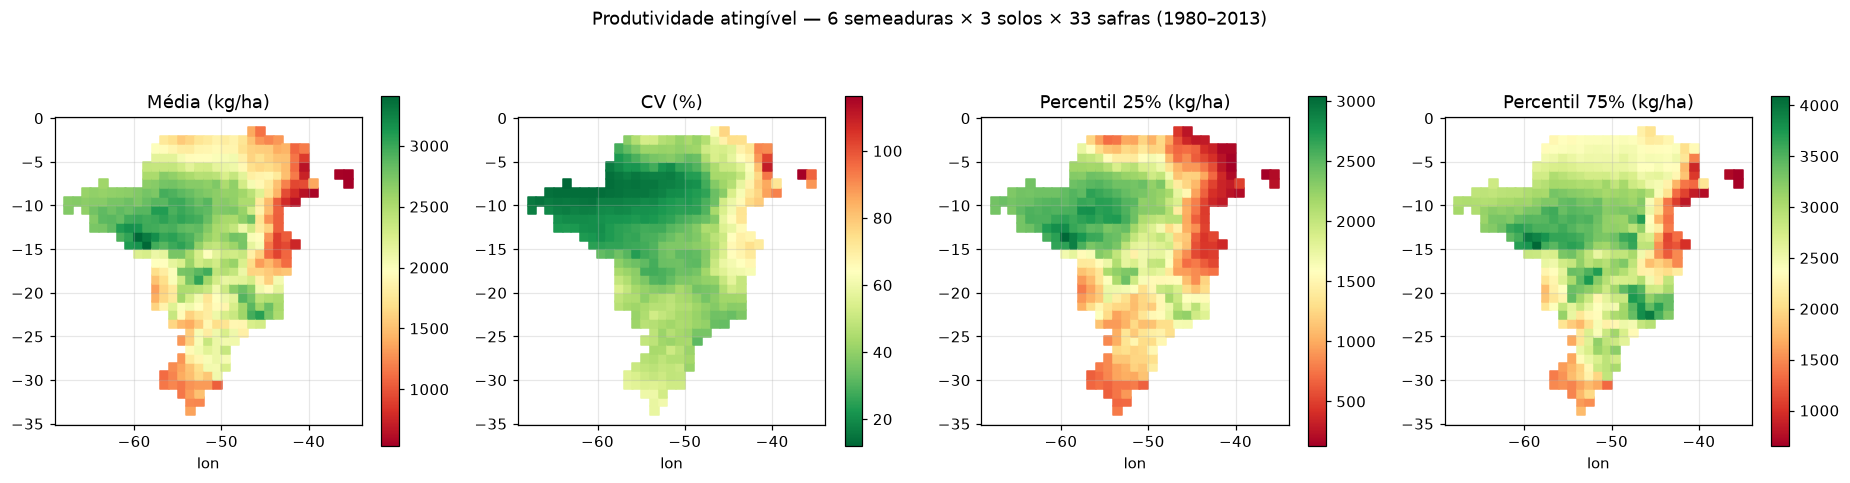

In [2]:
est = an.estatisticas_ponto(sim)
fig, axs = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, (c, tit, cmap) in zip(axs, [("media", "Média (kg/ha)", "RdYlGn"), ("cv", "CV (%)", "RdYlGn_r"),
                                     ("p25", "Percentil 25% (kg/ha)", "RdYlGn"), ("p75", "Percentil 75% (kg/ha)", "RdYlGn")]):
    sc = ax.scatter(est.lon, est.lat, c=est[c], cmap=cmap, marker="s", s=34)
    plt.colorbar(sc, ax=ax, shrink=0.8); ax.set_title(tit); ax.set_aspect("equal"); ax.set_xlabel("lon")
fig.suptitle("Produtividade atingível — 6 semeaduras × 3 solos × 33 safras (1980–2013)")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig2_replicada.png", bbox_inches="tight")

## Zonas homogêneas (equivalente à Fig. 3)

Ward com distância euclidiana sobre a matriz pontos × (6 semeaduras × 3 solos × 33 safras), com 10 grupos. As zonas replicadas são renumeradas pela maior sobreposição com as zonas digitalizadas da Fig. 3.

Índice de Rand ajustado = 0.45 | pontos na mesma zona após casamento = 67%


zona_bs,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,All
zona_rep_casada,,,,,,,,,,,
1,40,0,7,4,0,0,0,0,0,0,51
2,32,39,9,0,0,0,0,0,0,3,83
3,0,2,50,0,0,0,0,5,0,0,57
4,0,0,2,28,19,0,1,0,0,0,50
5,0,0,0,1,20,0,1,0,0,0,22
6,0,0,0,0,0,19,0,0,5,0,24
7,0,0,0,0,0,0,15,2,0,0,17
8,0,0,3,0,0,0,2,21,0,0,26
9,0,1,10,0,0,0,0,0,24,16,51


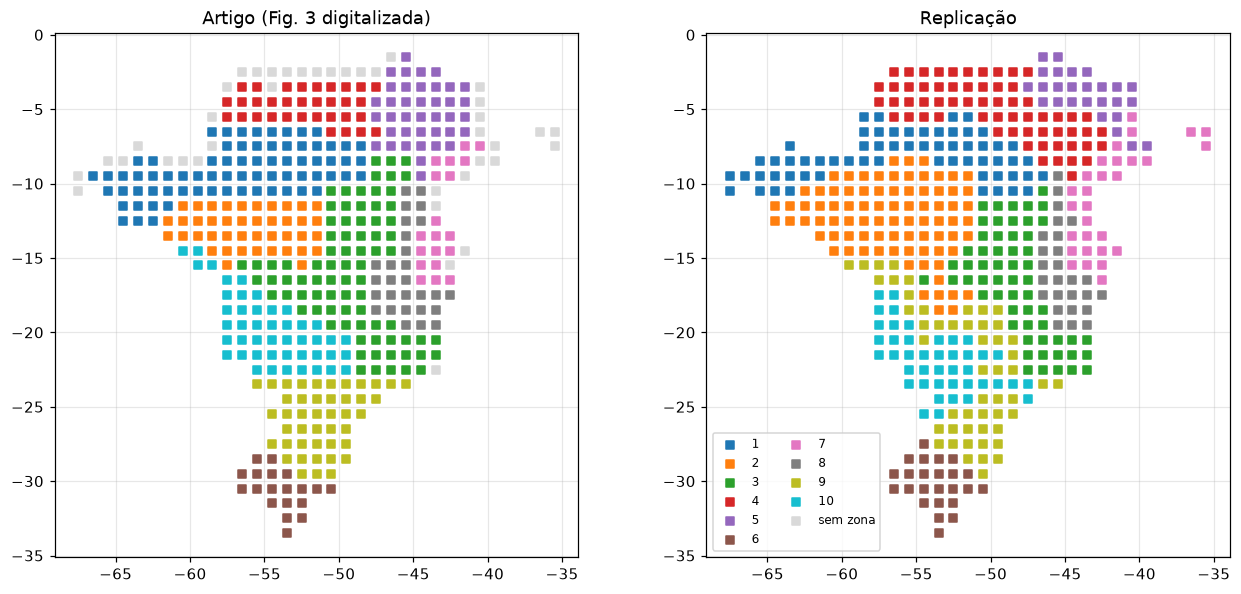

In [3]:
z = an.agrupar(sim, 10).merge(sim[["lon", "lat", "zona_bs"]].drop_duplicates(), on=["lon", "lat"])
z, ari, acerto = an.casar_zonas(z)
print(f"Índice de Rand ajustado = {ari:.2f} | pontos na mesma zona após casamento = {100*acerto:.0f}%")
cores = plt.cm.tab10.colors
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, col, tit in [(axs[0], "zona_bs", "Artigo (Fig. 3 digitalizada)"), (axs[1], "zona_rep_casada", "Replicação")]:
    for k in range(1, 11):
        s = z[z[col] == k]; ax.scatter(s.lon, s.lat, color=cores[k - 1], marker="s", s=30, label=str(k))
    s = z[z[col].isna()]; ax.scatter(s.lon, s.lat, color="0.85", marker="s", s=30, label="sem zona")
    ax.set_title(tit); ax.set_aspect("equal")
axs[1].legend(ncol=2, fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig3_zonas_comparacao.png", bbox_inches="tight")
pd.crosstab(z.zona_rep_casada, z.zona_bs, margins=True)

## Produtividade atingível por ponto e zona (equivalente à Fig. 4)

Cada caixa é um ponto (6 semeaduras × 3 solos × 33 safras), com os pontos ordenados pela zona do artigo.

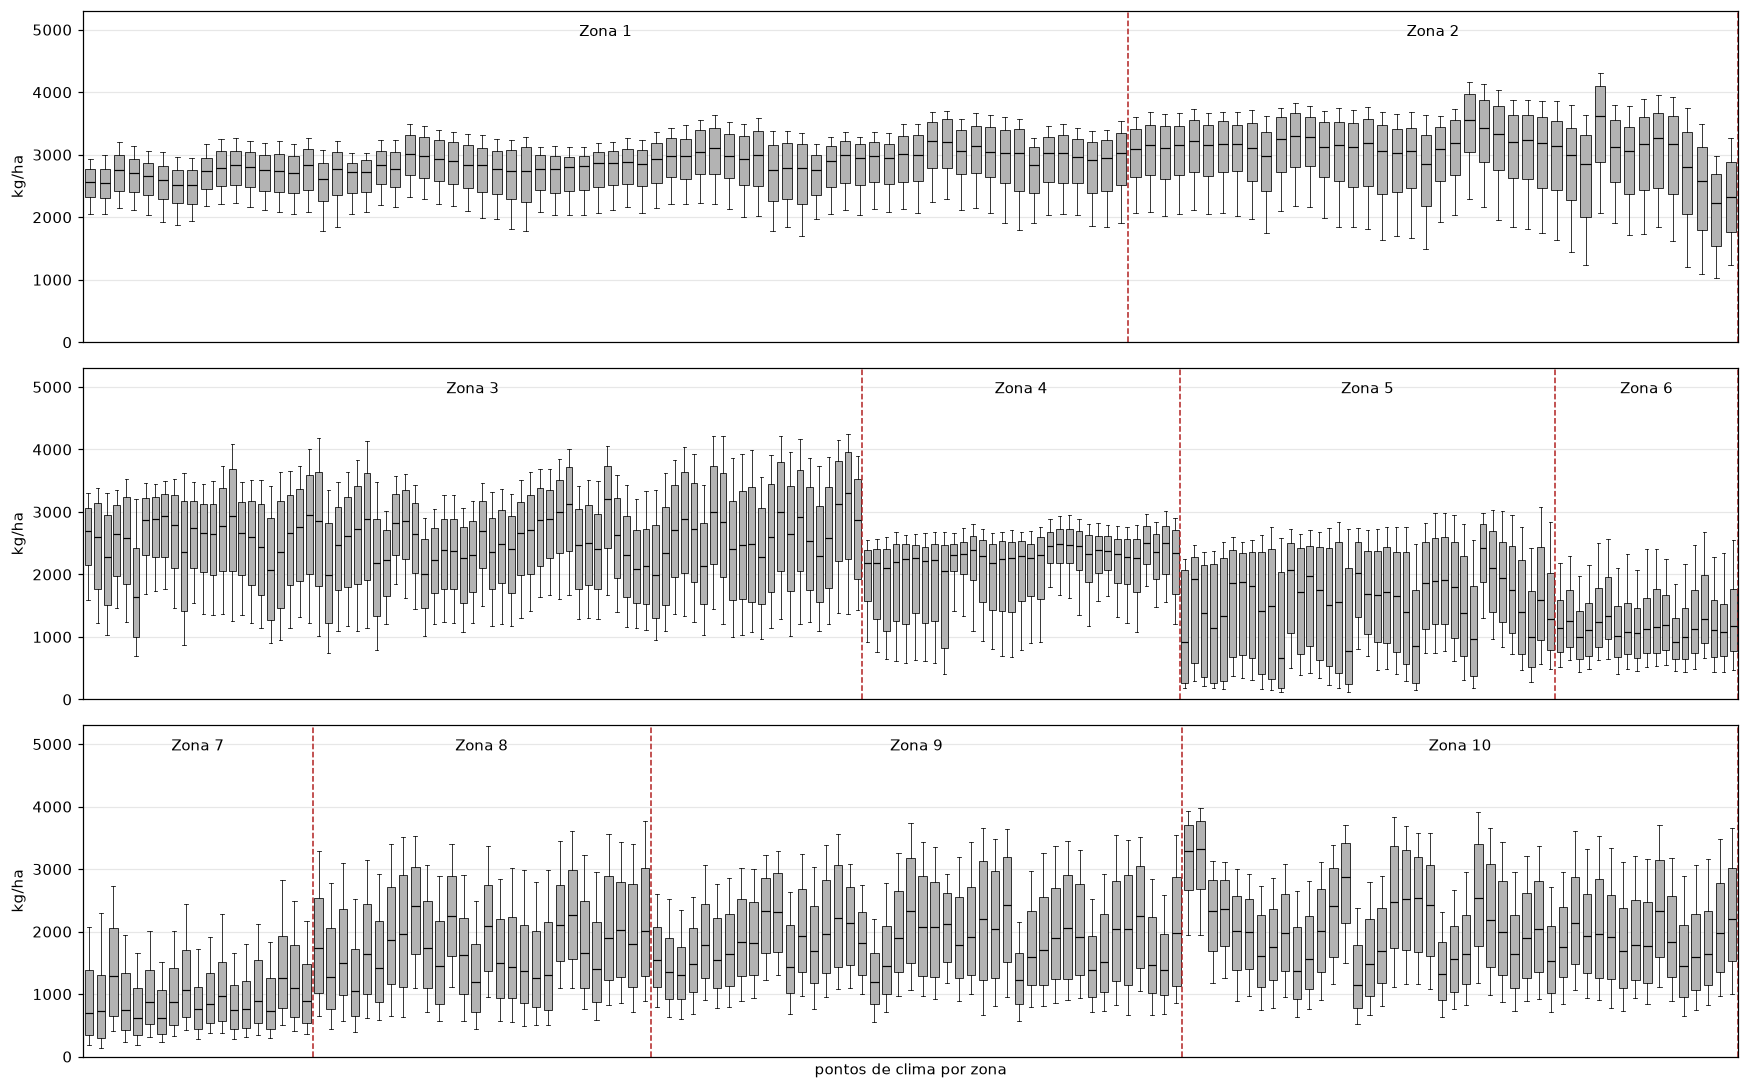

In [4]:
at = sim[(sim.cenario == "atingivel")].dropna(subset=["zona_bs"])
ordem = at.groupby(["zona_bs", "lat", "lon"]).size().reset_index().sort_values(["zona_bs", "lat"], ascending=[True, False])
fig, axs = plt.subplots(3, 1, figsize=(16, 10), sharey=True)
for ax, zonas in zip(axs, [(1, 2), (3, 4, 5, 6), (7, 8, 9, 10)]):
    o = ordem[ordem.zona_bs.isin(zonas)]
    dados = [at[(at.lon == r.lon) & (at.lat == r.lat)].HWAM.values for r in o.itertuples()]
    if not dados: continue
    ax.boxplot(dados, whis=(10, 90), sym="", widths=0.7, patch_artist=True,
               boxprops=dict(facecolor="0.7", lw=0.5), medianprops=dict(color="k", lw=0.8), whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5))
    pos = np.cumsum([0] + [int((o.zona_bs == zz).sum()) for zz in zonas])
    for a, b, zz in zip(pos[:-1], pos[1:], zonas):
        if b > a:
            ax.axvline(b + 0.5, color="firebrick", ls="--", lw=1); ax.text((a + b) / 2 + 0.5, 4900, f"Zona {zz}", ha="center")
    ax.set_xticks([]); ax.set_ylim(0, 5300); ax.set_ylabel("kg/ha")
axs[-1].set_xlabel("pontos de clima por zona")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig4_replicada.png", bbox_inches="tight")

## Potencial, atingível e impacto do estresse hídrico por zona (equivalente à Fig. 5a–c)

Caixas com bigodes nos percentis 10–90%, linha cheia na mediana e tracejada na média, como no artigo. Impacto relativo = 1 − Yw/Yp, por ponto × solo × semeadura × safra.

cenario potencial         atingivel         impacto       
             mean  median      mean  median    mean median
zona_bs                                                   
1.0       2950.81  2992.0   2760.40  2837.0    0.07   0.02
2.0       3372.59  3460.0   2931.35  3110.0    0.14   0.06
3.0       3419.54  3475.0   2507.08  2584.0    0.27   0.23
4.0       2673.33  2678.0   2094.93  2308.5    0.21   0.07
5.0       3015.68  2999.0   1565.77  1605.0    0.46   0.47
6.0       3095.25  3214.0   1268.05  1130.0    0.55   0.61
7.0       3788.83  3829.5   1052.27   848.5    0.72   0.78
8.0       3660.71  3734.0   1815.44  1679.0    0.50   0.53
9.0       2975.22  3144.0   1899.07  1769.0    0.35   0.33
10.0      3358.15  3460.0   2036.90  1943.0    0.39   0.40

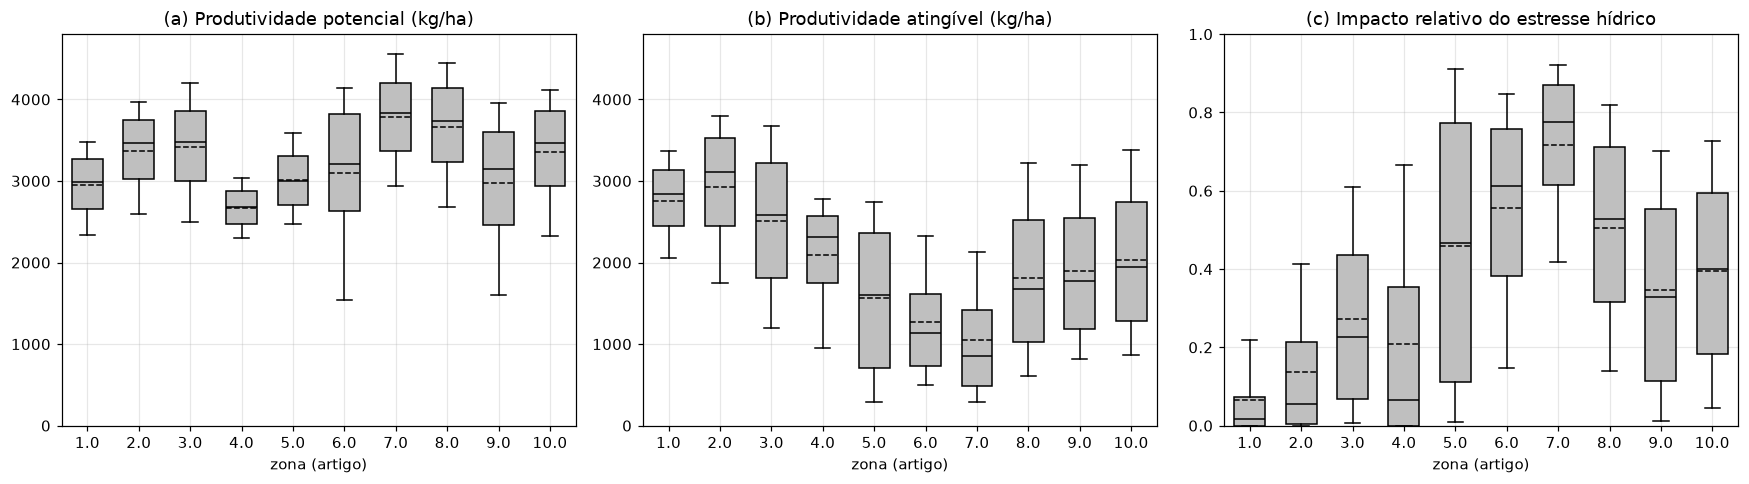

In [5]:
par = sim.pivot_table(index=["lon", "lat", "zona_bs", "solo", "semeadura", "safra"], columns="cenario",
                     values="HWAM", observed=True).reset_index().dropna(subset=["zona_bs"])
par["impacto"] = (1 - par.atingivel / par.potencial).clip(0, 1)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (c, tit) in zip(axs, [("potencial", "(a) Produtividade potencial (kg/ha)"), ("atingivel", "(b) Produtividade atingível (kg/ha)"),
                              ("impacto", "(c) Impacto relativo do estresse hídrico")]):
    zs = sorted(par.zona_bs.unique())
    ax.boxplot([par.loc[par.zona_bs == zz, c] for zz in zs], positions=zs, whis=(10, 90), sym="", widths=0.6, patch_artist=True,
               showmeans=True, meanline=True, meanprops=dict(color="k", ls="--", lw=1),
               boxprops=dict(facecolor="0.75"), medianprops=dict(color="k"))
    ax.set_title(tit); ax.set_xlabel("zona (artigo)")
axs[0].set_ylim(0, 4800); axs[1].set_ylim(0, 4800); axs[2].set_ylim(0, 1)
fig.tight_layout(); fig.savefig(DIR_FIG / "fig5_replicada.png", bbox_inches="tight")
par.groupby("zona_bs")[["potencial", "atingivel", "impacto"]].agg(["mean", "median"]).round(2)

## Números do texto × replicação (usando as zonas do artigo)

In [6]:
res = an.resumo_por_zona(sim, "zona_bs")
display(res)
comp = an.comparar_alvos(res)
comp.to_csv(DIR_FIG / "comparacao_alvos.csv", index=False)
comp

,mean_atingivel,mean_potencial,min_atingivel,min_potencial,max_atingivel,max_potencial,perda_pct
zona_bs,,,,,,,
1.0,2760.0,2951.0,358,1792,4114,4112,6.0
2.0,2931.0,3373.0,194,1618,4805,4884,13.0
3.0,2507.0,3420.0,82,1242,5115,5439,27.0
4.0,2095.0,2673.0,135,1885,3477,3504,22.0
5.0,1566.0,3016.0,11,1853,3913,4383,48.0
6.0,1268.0,3095.0,58,242,4141,4915,59.0
7.0,1052.0,3789.0,22,2224,4481,5440,72.0
8.0,1815.0,3661.0,82,1781,4851,5304,50.0
9.0,1899.0,2975.0,52,61,4614,4972,36.0


,variavel,zona,artigo,replicado,unidade,dif_pct
0,produtividade_atingivel_media,2,3155.0,2931.0,kg/ha,-7.1
1,produtividade_atingivel_media,1,2800.0,2760.0,kg/ha,-1.4
2,produtividade_atingivel_media,3,2800.0,2507.0,kg/ha,-10.5
3,produtividade_atingivel_media,6,1169.0,1268.0,kg/ha,8.5
4,produtividade_atingivel_media,7,945.0,1052.0,kg/ha,11.3
5,produtividade_potencial_media,4,2654.0,2673.0,kg/ha,0.7
6,produtividade_potencial_min,4,2164.0,1885.0,kg/ha,-12.9
7,produtividade_potencial_max,4,3074.0,3504.0,kg/ha,14.0
8,produtividade_potencial_min,todas,1244.0,61.0,kg/ha,-95.1
9,produtividade_potencial_max,todas,4600.0,5440.0,kg/ha,18.3


## Simulado × IBGE por microrregião (equivalente à Fig. 6)

Média atingível simulada (1980–2013, todas as combinações) contra a média do IBGE (2007–2016). Cada município com soja em 2016 é ligado ao ponto de clima mais próximo (até 0,75°), com média ponderada pela área de soja. O artigo não descreve como liga pontos a microrregiões; este é um critério nosso.

,n,r,sim_media,ibge_media
zona_bs,,,,
1.0,15.0,0.64,2755.16,2905.50
2.0,14.0,0.50,2957.39,3044.30
3.0,73.0,0.11,2533.54,2756.77
4.0,4.0,-0.56,2130.01,2867.19
5.0,16.0,0.44,1640.53,2569.43
6.0,17.0,0.52,1339.57,2256.17
7.0,1.0,NaN,886.97,3359.00
8.0,16.0,0.50,1954.76,2741.86
9.0,79.0,0.31,1902.78,2839.72


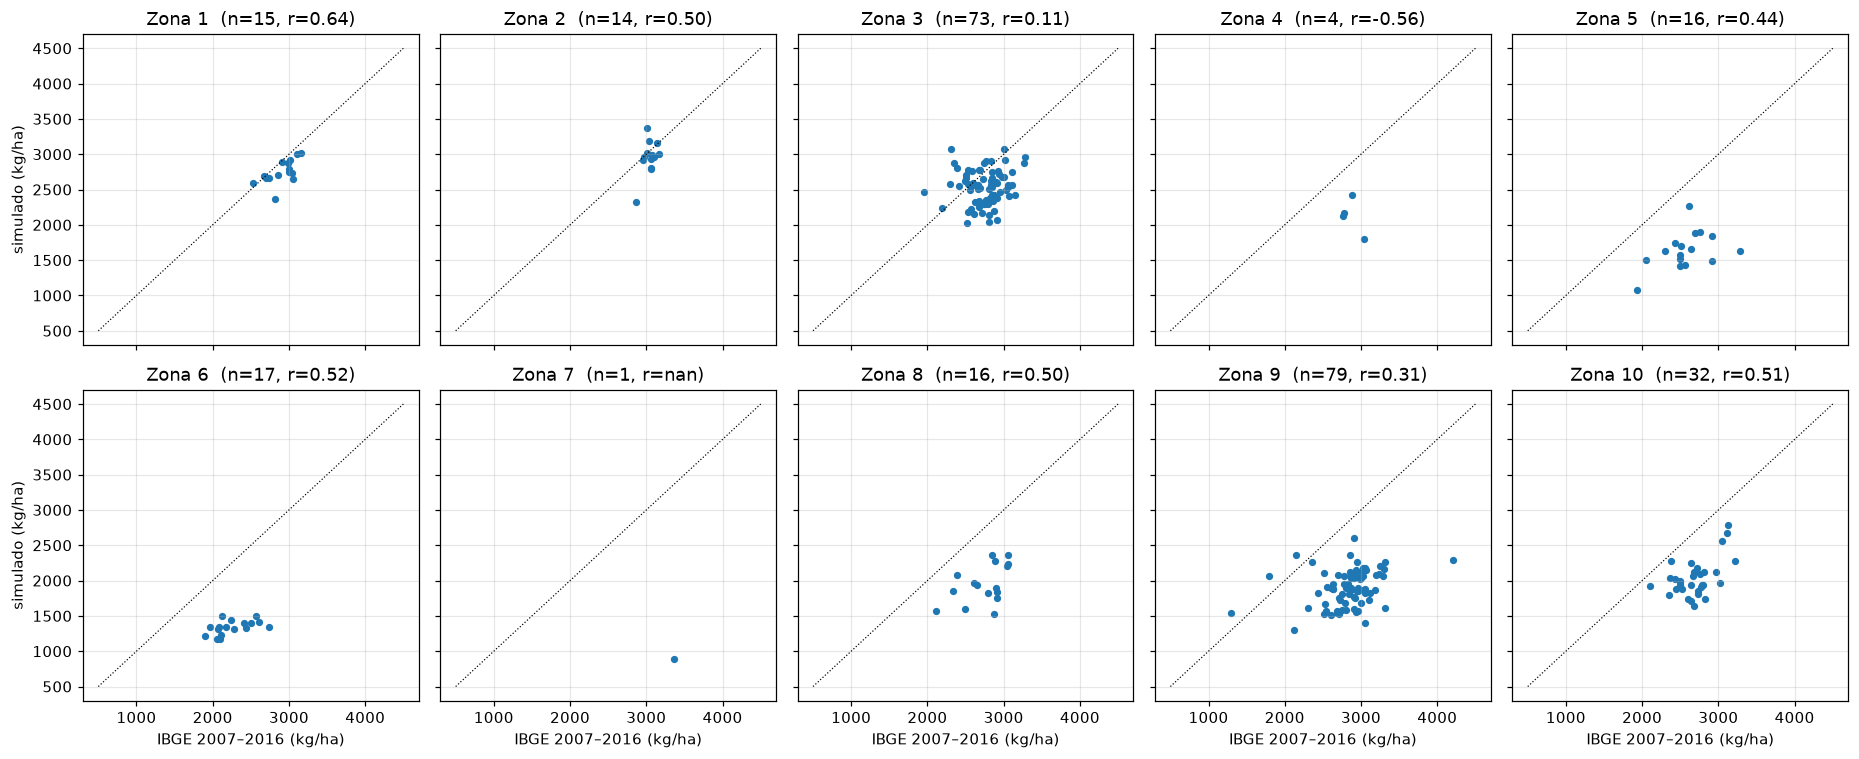

In [7]:
micro, r_zona = an.comparar_ibge_microrregiao(sim, est)
micro.to_csv(DIR_FIG / "fig6_microrregioes.csv", index=False)
fig, axs = plt.subplots(2, 5, figsize=(17, 7), sharex=True, sharey=True)
for ax, zz in zip(axs.flat, range(1, 11)):
    s = micro[micro.zona_bs == zz]
    ax.scatter(s.ibge, s.sim, s=14, color="tab:blue"); ax.plot([500, 4500], [500, 4500], "k:", lw=0.8)
    rr = r_zona.r.get(float(zz), np.nan)
    ax.set_title(f"Zona {zz}  (n={len(s)}, r={rr:.2f})" if len(s) else f"Zona {zz}")
for ax in axs[1]: ax.set_xlabel("IBGE 2007–2016 (kg/ha)")
for ax in axs[:, 0]: ax.set_ylabel("simulado (kg/ha)")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig6_replicada.png", bbox_inches="tight")
r_zona

## Fenologia: dias após a semeadura até E, R1 e R7 (barras da Fig. 7)

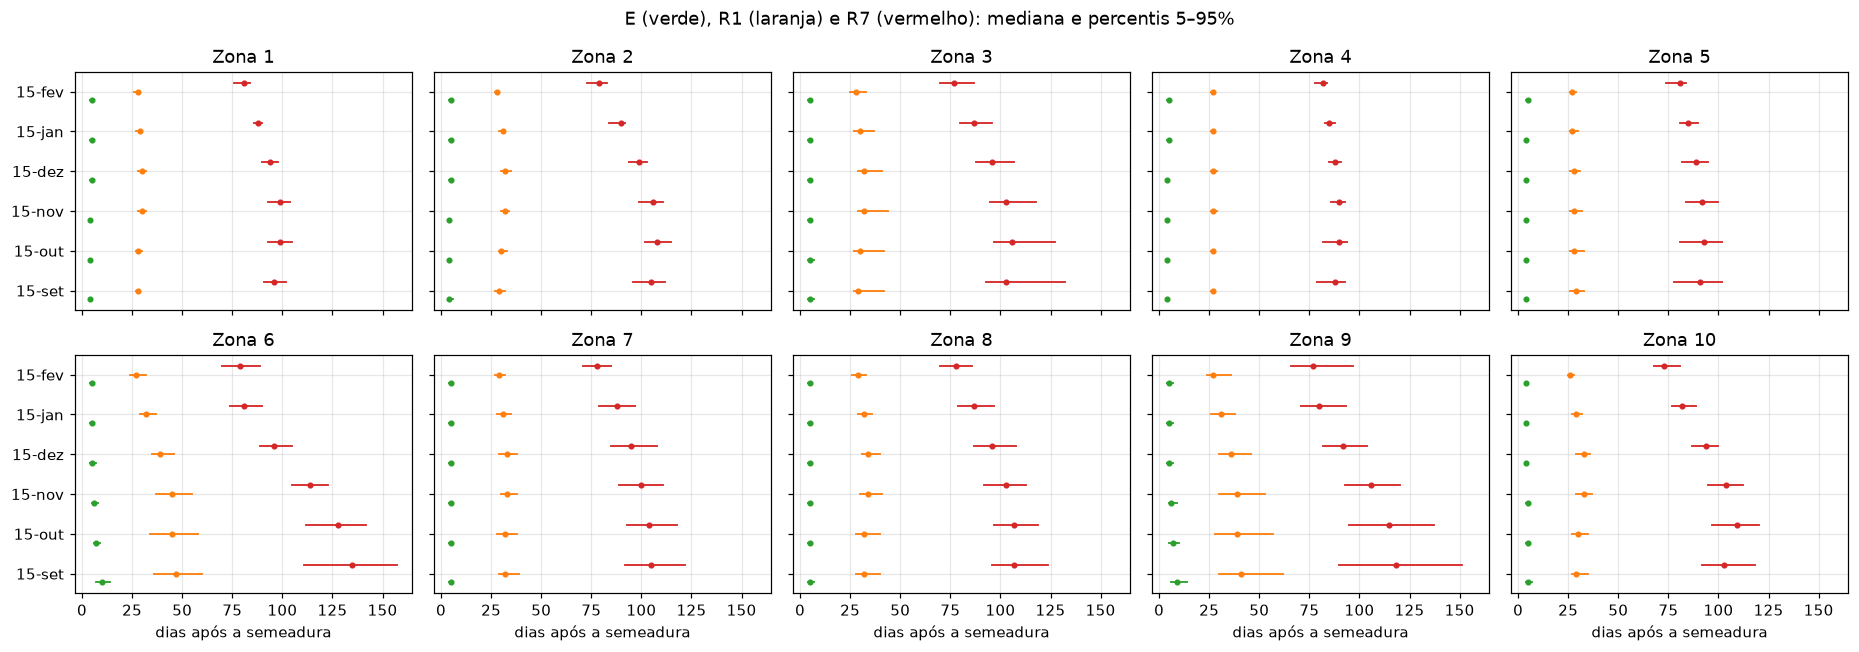

In [8]:
fen = (sim[sim.cenario == "atingivel"].dropna(subset=["zona_bs"])
       .groupby(["zona_bs", "semeadura"], observed=True)[["E_das", "R1_das", "R7_das"]]
       .quantile([.05, .25, .5, .75, .95]).unstack().round(0))
fen.to_csv(DIR_FIG / "fenologia_percentis_zona_semeadura.csv")
fig, axs = plt.subplots(2, 5, figsize=(17, 6), sharex=True, sharey=True)
for ax, zz in zip(axs.flat, range(1, 11)):
    s = sim[(sim.zona_bs == zz) & (sim.cenario == "atingivel")]
    for i, sem in enumerate(an.ORDEM_SEMEADURA):
        q = s[s.semeadura == sem][["E_das", "R1_das", "R7_das"]].quantile([.05, .5, .95])
        for j, (st, cor) in enumerate([("E_das", "tab:green"), ("R1_das", "tab:orange"), ("R7_das", "tab:red")]):
            y = i + (j - 1) * 0.22
            ax.plot([q.loc[.05, st], q.loc[.95, st]], [y, y], color=cor, lw=1.2); ax.plot(q.loc[.5, st], y, "o", color=cor, ms=3)
    ax.set_title(f"Zona {zz}"); ax.set_yticks(range(6), an.ORDEM_SEMEADURA)
for ax in axs[1]: ax.set_xlabel("dias após a semeadura")
fig.suptitle("E (verde), R1 (laranja) e R7 (vermelho): mediana e percentis 5–95%")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig7_fenologia_replicada.png", bbox_inches="tight")

## Próximos passos

- Comparação com o IBGE por microrregião, 2007–2016 (Fig. 6). Requer estender o clima até 2016.
- Padrões de déficit hídrico (Figs. 7–8). Requer as saídas diárias de WSPD.
- Sensibilidade às suposições: ET (FAO-56 × Priestley-Taylor), água disponível do argiloso (150 × 120 mm), ecótipo.